# Network Graph (Node-Link Diagram)

**Family:** Flow &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Flow:* Show the volume or intensity of movement between states, stages, or places.

## Design purpose

Entities are drawn as nodes and relationships as edges. A force-directed layout pulls connected nodes together, so clusters, hubs, and bridges show in the structure itself.

## When to use

- Show relationships: collaboration, referral, citation, or communication networks
- Find communities, central hubs, and isolated nodes
- Show topology where who connects to whom matters more than amounts

## Avoid when

- There are hundreds of densely connected nodes, a 'hairball' (filter, aggregate, or use an adjacency matrix)
- Readers need to compare quantitative values precisely

## Alternatives

- Adjacency matrix heatmap
- Arc diagram
- Chord diagram

## Design tips

- Size nodes by degree or another importance measure
- Color by community (at most 8 groups) and keep edges thin and light

## Example

Co-authorship network of 40 researchers in three research groups (synthetic).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import networkx as nx

### Data

In [2]:
G = nx.planted_partition_graph(3, 13, p_in=0.35, p_out=0.02, seed=4)
group = {n: n // 13 for n in G.nodes}
# one bridge author connected to all groups
G.add_node(39)
group[39] = 3
G.add_edges_from([(39, 0), (39, 14), (39, 27), (39, 5)])
G.remove_nodes_from(list(nx.isolates(G)))
print(G)

Graph named 'stochastic_block_model' with 39 nodes and 94 edges


### Plot

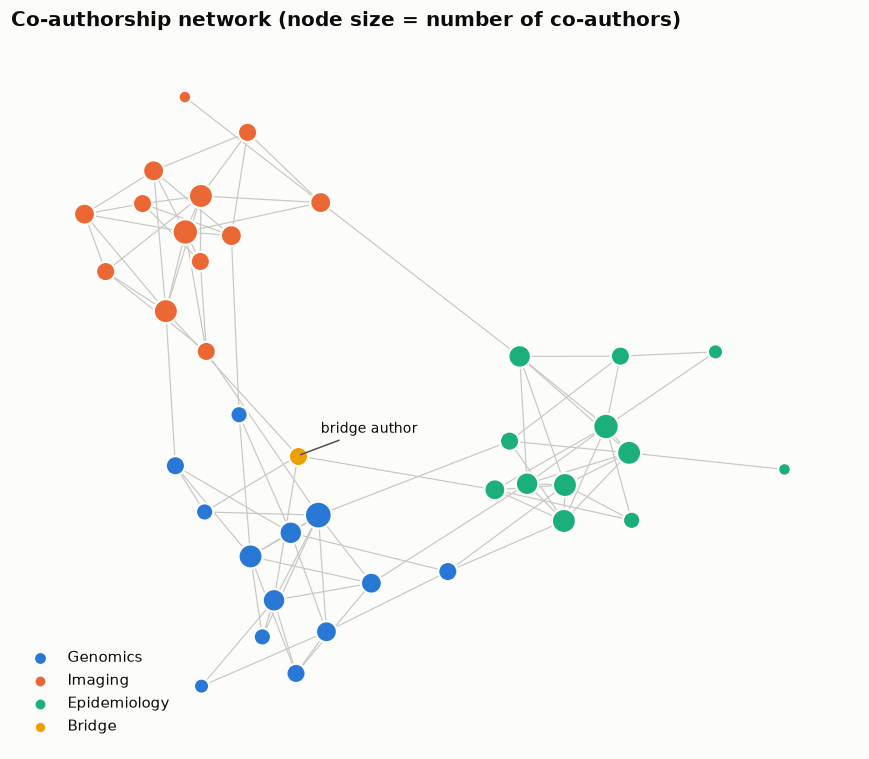

In [3]:
pos = nx.spring_layout(G, seed=7, k=0.35)
deg = dict(G.degree())
group_names = ["Genomics", "Imaging", "Epidemiology", "Bridge"]
fig, ax = plt.subplots(figsize=(8, 7))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#c9c8c3", width=0.8)
for g in range(4):
    ns = [n for n in G.nodes if group[n] == g]
    nx.draw_networkx_nodes(G, pos, nodelist=ns, ax=ax, node_color=PALETTE[g],
                           node_size=[40 + 30 * deg[n] for n in ns],
                           edgecolors="#fcfcfb", linewidths=1.5, label=group_names[g])
ax.annotate("bridge author", pos[39], xytext=(15, 15), textcoords="offset points",
            fontsize=9, arrowprops=dict(arrowstyle="-", color="#52514e"))
ax.legend(loc="lower left", markerscale=0.6)
ax.set_title("Co-authorship network (node size = number of co-authors)")
ax.axis("off")
fig.tight_layout()
plt.show()

## How to read it

Each dot is a researcher and each line joins two researchers who have co-authored at least one paper. The three groups form dense clusters, and the yellow bridge author links them all.

---
Standalone script: [`network_graph.py`](network_graph.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)